# 8. Systems and Higher-Order Equations

Most models involve more than one unknown: positions **and** velocities, predators **and** prey, several chemical concentrations. This section shows that every method in the chapter applies unchanged to systems, how higher-order equations are rewritten as systems, and what can go wrong over long simulations of oscillating systems.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

## 8.1 Systems of first-order equations

A system of $m$ first-order equations

$$
\begin{aligned}
y_1' &= f_1(x, y_1, \dots, y_m)\\
&\ \ \vdots\\
y_m' &= f_m(x, y_1, \dots, y_m)
\end{aligned}
$$

is written in vector form as

$$\mathbf{y}' = \mathbf{f}(x, \mathbf{y}), \qquad \mathbf{y}(x_0) = \mathbf{y}_0, \qquad \mathbf{y} \in \mathbb{R}^m.$$

**Every method carries over word for word**: the slopes $k_i$ simply become vectors. For example, Euler is $\mathbf{y}_{n+1} = \mathbf{y}_n + h\,\mathbf{f}(x_n, \mathbf{y}_n)$, and RK4 uses four vector stages. The theory carries over too, with $|\cdot|$ replaced by a vector norm and $\partial f/\partial y$ replaced by the **Jacobian matrix** $J = (\partial f_i/\partial y_j)$.

With NumPy the code hardly changes: store the solution as an array of shape $(n+1, m)$. The functions below also work for scalar equations.

In [2]:
def euler(f, x0, y0, h, n):
    y0 = np.asarray(y0, dtype=float)
    x, y = x0 + h * np.arange(n + 1), np.zeros((n + 1,) + y0.shape)
    y[0] = y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
    return x, y

def rk4(f, x0, y0, h, n):
    y0 = np.asarray(y0, dtype=float)
    x, y = x0 + h * np.arange(n + 1), np.zeros((n + 1,) + y0.shape)
    y[0] = y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return x, y

## 8.2 Higher-order equations as systems

An equation of order $m$,

$$y^{(m)} = g\big(x, y, y', \dots, y^{(m-1)}\big),$$

becomes a first-order system by introducing the unknowns $u_1 = y$, $u_2 = y'$, ..., $u_m = y^{(m-1)}$:

$$u_1' = u_2, \qquad u_2' = u_3, \qquad \dots, \qquad u_m' = g(x, u_1, u_2, \dots, u_m).$$

The initial conditions $y(x_0), y'(x_0), \dots, y^{(m-1)}(x_0)$ become the initial vector $\mathbf{u}_0$.

**Example: a damped oscillator.**

$$y'' + 0.4\,y' + 4y = 0, \qquad y(0) = 1, \quad y'(0) = 0.$$

With $u_1 = y$ and $u_2 = y'$:

$$u_1' = u_2, \qquad u_2' = -4u_1 - 0.4u_2, \qquad \mathbf{u}(0) = (1, 0).$$

The characteristic equation $r^2 + 0.4r + 4 = 0$ gives $r = -0.2 \pm i\omega_d$ with $\omega_d = \sqrt{3.96}$, so the exact solution is

$$y = e^{-0.2x}\left(\cos\omega_d x + \frac{0.2}{\omega_d}\sin\omega_d x\right).$$

max |error| in y over [0, 15]: 5.00e-05


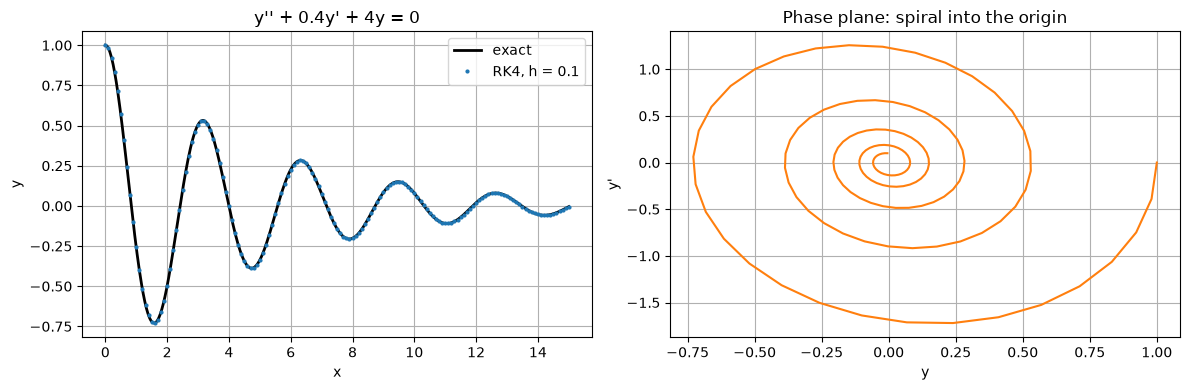

In [3]:
damped = lambda x, u: np.array([u[1], -4 * u[0] - 0.4 * u[1]])
wd = np.sqrt(3.96)
damped_exact = lambda x: np.exp(-0.2 * x) * (np.cos(wd * x) + 0.2 / wd * np.sin(wd * x))

x, u = rk4(damped, 0, [1, 0], 0.1, 150)
xf = np.linspace(0, 15, 600)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(xf, damped_exact(xf), "k", lw=2, label="exact")
axes[0].plot(x, u[:, 0], ".", ms=4, label="RK4, h = 0.1")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y"); axes[0].set_title("y'' + 0.4y' + 4y = 0"); axes[0].legend()
axes[1].plot(u[:, 0], u[:, 1], "C1")
axes[1].set_xlabel("y"); axes[1].set_ylabel("y'"); axes[1].set_title("Phase plane: spiral into the origin")
plt.tight_layout()
print(f"max |error| in y over [0, 15]: {np.max(np.abs(u[:, 0] - damped_exact(x))):.2e}")

## 8.3 Long simulations and conserved quantities

The undamped oscillator $y'' = -y$, as the system

$$u' = v, \qquad v' = -u,$$

has solutions that move round circles in the $(u, v)$ plane forever. The **energy** $E = \tfrac12(u^2 + v^2)$ is conserved exactly. The eigenvalues of the system matrix are $\pm i$, so this is the imaginary-axis case of [Section 5.3](05-stability-and-stiffness.ipynb).

* **Euler:** $(u_{n+1}, v_{n+1}) = (u_n + hv_n,\ v_n - hu_n)$, so $u_{n+1}^2 + v_{n+1}^2 = (1 + h^2)(u_n^2 + v_n^2)$. The energy grows by the factor $1 + h^2$ **every step**: the orbit spirals outwards.
* **RK4:** the energy is multiplied by $|R(ih)|^2 = 1 - \frac{h^6}{72} + \frac{h^8}{576}$ per step: a very slow inward drift.
* **Symplectic (semi-implicit) Euler:** update the velocity first and use the *new* velocity for the position:

$$v_{n+1} = v_n - h\,u_n, \qquad u_{n+1} = u_n + h\,v_{n+1}.$$

  It is still only order 1 and costs the same as Euler, but it preserves areas in the phase plane (the update matrix has determinant 1). As a result its energy error stays **bounded**: it oscillates but never drifts, however long the simulation.

Euler            : relative energy error at x = 100: +2.10e+04
RK4              : relative energy error at x = 100: -1.39e-05
Symplectic Euler : relative energy error at x = 100: +4.26e-02


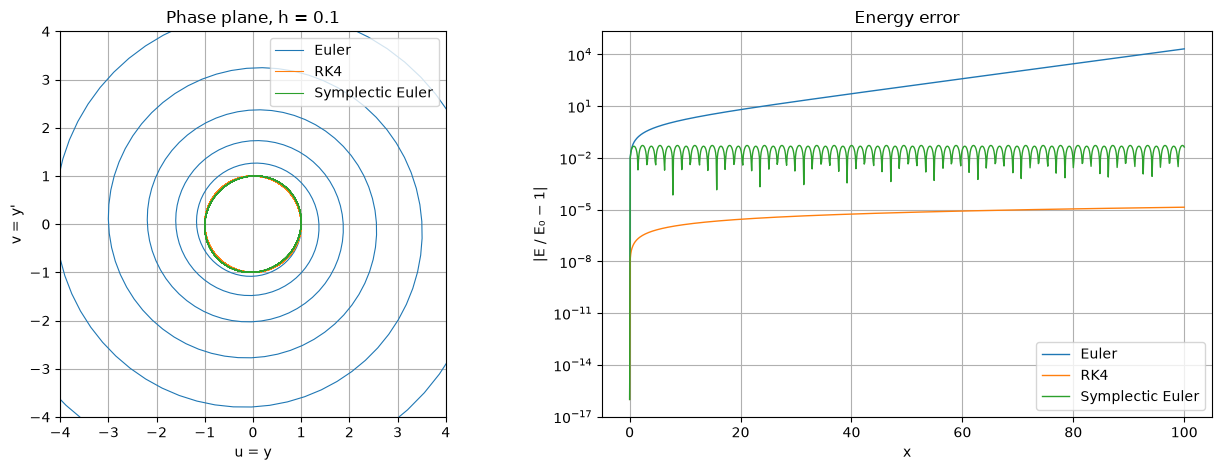

In [4]:
osc = lambda x, u: np.array([u[1], -u[0]])

def symplectic_euler(h, n, u0, v0):
    u, v = np.zeros(n + 1), np.zeros(n + 1)
    u[0], v[0] = u0, v0
    for i in range(n):
        v[i + 1] = v[i] - h * u[i]
        u[i + 1] = u[i] + h * v[i + 1]
    return u, v

h, n = 0.1, 1000                                    # x up to 100, about 16 periods
_, ue = euler(osc, 0, [1, 0], h, n)
_, ur = rk4(osc, 0, [1, 0], h, n)
us, vs = symplectic_euler(h, n, 1, 0)
results = {"Euler": (ue[:, 0], ue[:, 1]), "RK4": (ur[:, 0], ur[:, 1]), "Symplectic Euler": (us, vs)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
t = h * np.arange(n + 1)
for name, (u, v) in results.items():
    axes[0].plot(u, v, lw=0.8, label=name)
    energy = 0.5 * (u**2 + v**2)
    axes[1].semilogy(t, np.abs(energy / 0.5 - 1) + 1e-16, lw=1, label=name)
    print(f"{name:17s}: relative energy error at x = 100: {energy[-1] / 0.5 - 1:+.2e}")
axes[0].set_xlim(-4, 4); axes[0].set_ylim(-4, 4); axes[0].set_aspect("equal")
axes[0].set_xlabel("u = y"); axes[0].set_ylabel("v = y'"); axes[0].set_title("Phase plane, h = 0.1"); axes[0].legend(loc="upper right")
axes[1].set_xlabel("x"); axes[1].set_ylabel("|E / E₀ − 1|"); axes[1].set_title("Energy error")
axes[1].legend()
plt.tight_layout()

* Euler's energy has grown by a factor $(1.01)^{1000} \approx 2 \times 10^4$: the "oscillator" is flying apart.
* RK4's energy error is tiny but grows steadily with time.
* Symplectic Euler's energy error is much larger than RK4's (order 1 against order 4), but it **does not grow**: it oscillates within a fixed band for as long as the simulation runs. RK4's error keeps growing linearly, so over a long enough run (here, hundreds of thousands of time units) it would eventually overtake. Higher-order symplectic methods get both benefits.

For long simulations of conservative systems (planetary orbits, molecular dynamics, particle accelerators) the qualitative behaviour matters more than the local error, so **geometric integrators** are used: symplectic Euler, the Störmer–Verlet (leapfrog) method, and higher-order symplectic methods.

## 8.4 The nonlinear pendulum

A pendulum of length $L$ obeys

$$\theta'' = -\frac{g}{L}\sin\theta.$$

For small angles $\sin\theta \approx \theta$, which gives simple harmonic motion with period $T_0 = 2\pi\sqrt{L/g}$ independent of the amplitude. For large swings the period **increases**. The exact period for a release from rest at angle $\theta_0$ is

$$T = 4\sqrt{\frac{L}{g}}\;K\!\left(\sin\frac{\theta_0}{2}\right),$$

where $K(k)$ is the complete elliptic integral of the first kind. It can be computed very accurately with the arithmetic–geometric mean: $K(k) = \dfrac{\pi}{2\,\operatorname{AGM}\big(1, \sqrt{1 - k^2}\big)}$.

We take $g/L = 1$ (so $T_0 = 2\pi$), integrate with RK4, and measure the period from the time of the first zero crossing of $\theta$, which is $T/4$.

    θ0   RK4 period  exact period  difference  small-angle 2π
   10°      6.29517       6.29517     3.8e-08         6.28319
   45°      6.53435       6.53435     4.4e-08         6.28319
   90°      7.41630       7.41630     3.0e-08         6.28319


  135°      9.60038       9.60038     6.5e-09         6.28319
  170°     15.32697      15.32697     6.3e-08         6.28319


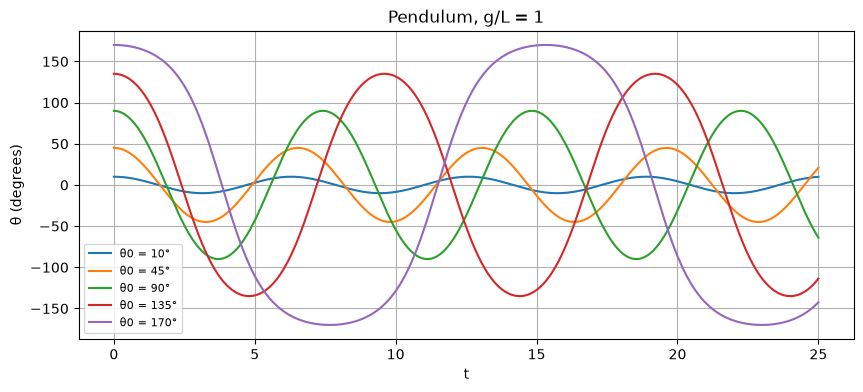

In [5]:
pend = lambda t, s: np.array([s[1], -np.sin(s[0])])

def agm(a, b):
    while abs(a - b) > 1e-15:
        a, b = (a + b) / 2, np.sqrt(a * b)
    return a

K = lambda k: np.pi / (2 * agm(1.0, np.sqrt(1 - k**2)))

h, n = 0.01, 2500
print(f"{'θ0':>6} {'RK4 period':>12} {'exact period':>13} {'difference':>11} {'small-angle 2π':>15}")
fig, ax = plt.subplots(figsize=(10, 4))
for deg in [10, 45, 90, 135, 170]:
    th0 = np.radians(deg)
    t, s = rk4(pend, 0, [th0, 0], h, n)
    i = np.argmax(s[:, 0] < 0)                                      # first step with θ < 0
    t_cross = t[i - 1] + h * s[i - 1, 0] / (s[i - 1, 0] - s[i, 0])  # linear interpolation
    T_num, T_exact = 4 * t_cross, 4 * K(np.sin(th0 / 2))
    print(f"{deg:5d}° {T_num:12.5f} {T_exact:13.5f} {T_num - T_exact:11.1e} {2 * np.pi:15.5f}")
    ax.plot(t, np.degrees(s[:, 0]), label=f"θ0 = {deg}°")
ax.set_xlabel("t"); ax.set_ylabel("θ (degrees)"); ax.set_title("Pendulum, g/L = 1")
ax.legend(loc="lower left", fontsize=8);

The RK4 periods agree with the elliptic-integral formula to about 7–8 significant figures. (Linear interpolation is enough to locate the zero crossing this accurately because $\theta'' = -\sin\theta \approx 0$ there, so $\theta$ is almost exactly linear near the crossing.) At $170^\circ$ the period is more than twice the small-angle value, and the motion is visibly not sinusoidal: the pendulum lingers near the top of its swing.

## 8.5 Predator–prey: the Lotka–Volterra equations

Let $x$ be a prey population and $y$ a predator population:

$$x' = \alpha x - \beta xy, \qquad y' = \delta xy - \gamma y.$$

Prey grow at rate $\alpha$ and are eaten at a rate proportional to encounters $xy$; predators grow by eating and die at rate $\gamma$. The populations cycle around the equilibrium $(\gamma/\delta,\ \alpha/\beta)$, and the quantity

$$V(x, y) = \delta x - \gamma\ln x + \beta y - \alpha\ln y$$

is **conserved** (Exercise 4), so every exact orbit is a closed curve. A good method should keep $V$ nearly constant.

We use $\alpha = 1.1$, $\beta = 0.4$, $\gamma = 0.4$, $\delta = 0.1$ and start from $x = y = 10$.

Euler: V changes by +2.11e+00 over t ∈ [0, 50]
RK4  : V changes by -1.70e-05 over t ∈ [0, 50]


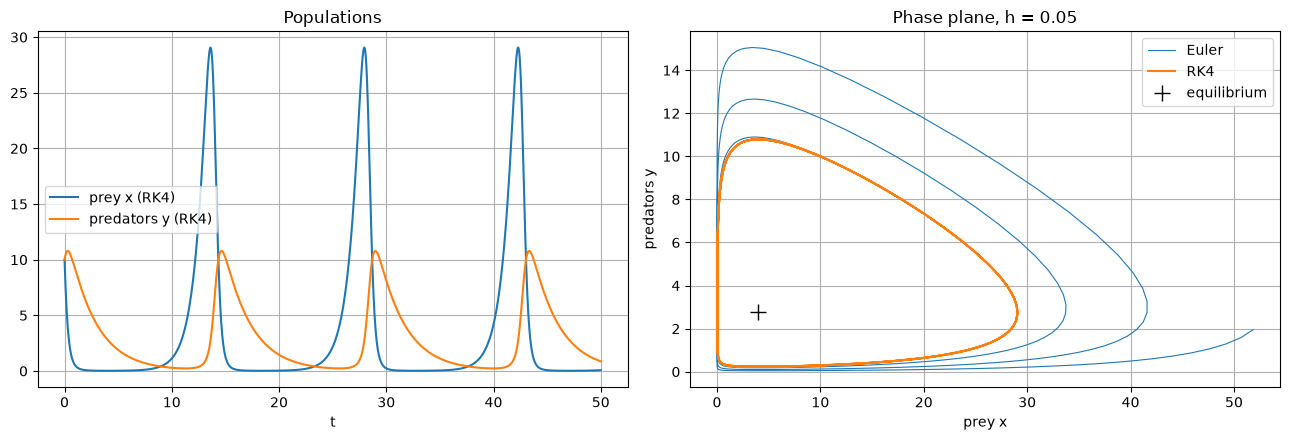

In [6]:
al, be, ga, de = 1.1, 0.4, 0.4, 0.1
lv = lambda t, z: np.array([al * z[0] - be * z[0] * z[1], de * z[0] * z[1] - ga * z[1]])
V = lambda z: de * z[..., 0] - ga * np.log(z[..., 0]) + be * z[..., 1] - al * np.log(z[..., 1])

h, n = 0.05, 1000                                    # t up to 50
t, ze = euler(lv, 0, [10, 10], h, n)
_, zr = rk4(lv, 0, [10, 10], h, n)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(t, zr[:, 0], label="prey x (RK4)")
axes[0].plot(t, zr[:, 1], label="predators y (RK4)")
axes[0].set_xlabel("t"); axes[0].set_title("Populations"); axes[0].legend()
axes[1].plot(ze[:, 0], ze[:, 1], lw=0.8, label="Euler")
axes[1].plot(zr[:, 0], zr[:, 1], lw=1.5, label="RK4")
axes[1].plot(ga / de, al / be, "k+", ms=12, label="equilibrium")
axes[1].set_xlabel("prey x"); axes[1].set_ylabel("predators y"); axes[1].set_title("Phase plane, h = 0.05")
axes[1].legend()
plt.tight_layout()
for name, z in [("Euler", ze), ("RK4", zr)]:
    print(f"{name:5s}: V changes by {V(z[-1]) - V(z[0]):+.2e} over t ∈ [0, 50]")

RK4's orbit closes on itself and $V$ is conserved to many digits. Euler's orbit spirals outwards, so its populations swing more and more wildly: a qualitatively wrong prediction, caused only by the numerical method.

## 8.6 Stiff systems

For a linear system $\mathbf{y}' = A\mathbf{y}$, each eigenvalue $\lambda_i$ of $A$ behaves like its own test equation $y' = \lambda_i y$. An explicit method is stable only if $h\lambda_i$ lies in its stability region for **every** eigenvalue. For nonlinear systems the same applies to the eigenvalues of the Jacobian $J$.

A system is stiff when its eigenvalues have very different sizes: the fast ones force a tiny step even after their components have decayed, while the solution is governed by the slow ones. The **stiffness ratio** $\max|\operatorname{Re}\lambda_i| / \min|\operatorname{Re}\lambda_i|$ measures this.

In [7]:
A = np.array([[-500.5, 499.5],
              [499.5, -500.5]])
lams = np.linalg.eigvals(A)
print(f"eigenvalues: {np.sort(lams)}")
print(f"stiffness ratio: {max(abs(lams)) / min(abs(lams)):.0f}")
print(f"RK4 stability limit: h < 2.785 / {max(abs(lams)):.0f} = {2.785 / max(abs(lams)):.5f}")
print(f"steps RK4 needs to reach x = 10 (the slow mode e^(−x) needs x ≈ 10 to decay): {10 / (2.785 / max(abs(lams))):,.0f}")

eigenvalues: [-1000.+0.j    -1.+0.j]
stiffness ratio: 1000
RK4 stability limit: h < 2.785 / 1000 = 0.00279
steps RK4 needs to reach x = 10 (the slow mode e^(−x) needs x ≈ 10 to decay): 3,591


The slow component $e^{-x}$ needs an interval of length about 10 to decay, but stability limits RK4 to $h < 0.0028$: more than 3,500 steps, nearly all of them dictated by a component that vanished after $x \approx 0.01$. An implicit method could take steps of $0.1$ or more. Systems like this are typical in chemical kinetics and in heat-flow problems discretised in space.

## 8.7 Summary

* Every method applies to systems $\mathbf{y}' = \mathbf{f}(x, \mathbf{y})$ unchanged; in NumPy, just use arrays.
* An equation of order $m$ becomes a system of $m$ first-order equations for $y, y', \dots, y^{(m-1)}$.
* For oscillating and conservative systems, watch the conserved quantities: Euler adds energy, RK4 loses it very slowly, symplectic methods keep it bounded forever.
* Stability for systems is governed by the eigenvalues of the Jacobian; widely spread eigenvalues mean stiffness.

## Exercises

1. Write $y^{\prime\prime\prime} - xy' + y = 0$ as a first-order system.
2. Show that Euler applied to $u' = v$, $v' = -u$ multiplies $u^2 + v^2$ by exactly $1 + h^2$ each step.
3. Use the pendulum code to find the period for $\theta_0 = 179^\circ$. How many times longer is it than the small-angle period?
4. Show that $V = \delta x - \gamma\ln x + \beta y - \alpha\ln y$ is constant along solutions of the Lotka–Volterra equations.

**Answers**

1. $u_1 = y$, $u_2 = y'$, $u_3 = y''$: $\ u_1' = u_2$, $\ u_2' = u_3$, $\ u_3' = x\,u_2 - u_1$.
2. $(u + hv)^2 + (v - hu)^2 = u^2 + v^2 + h^2(u^2 + v^2)$; the cross terms $2huv$ cancel.
3. See the cell below.
4. $\dfrac{dV}{dt} = \Big(\delta - \dfrac{\gamma}{x}\Big)(\alpha x - \beta xy) + \Big(\beta - \dfrac{\alpha}{y}\Big)(\delta xy - \gamma y) = (\delta x - \gamma)(\alpha - \beta y) + (\beta y - \alpha)(\delta x - \gamma) = 0.$

In [8]:
th0 = np.radians(179)
t, s = rk4(pend, 0, [th0, 0], 0.01, 3000)
i = np.argmax(s[:, 0] < 0)
T_num = 4 * (t[i - 1] + 0.01 * s[i - 1, 0] / (s[i - 1, 0] - s[i, 0]))
print(f"3.  T(179°) ≈ {T_num:.4f} (exact {4 * K(np.sin(th0 / 2)):.4f}), which is {T_num / (2 * np.pi):.2f} × the small-angle period")

3.  T(179°) ≈ 24.5111 (exact 24.5111), which is 3.90 × the small-angle period
